# Vehicle Type Classification — data plots for the report

Every figure is saved as a PNG in `figures_report/` (150 dpi) so it can be dropped straight into the report. Class colours are fixed everywhere: **class 0 = blue, class 1 = orange, class 2 = teal**.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import LinearSegmentedColormap

SEED = 42; np.random.seed(SEED)
for d in ["data", ".", "..", "/kaggle/input/vehicle-type-classification"]:
    if os.path.exists(f"{d}/vehicle_train_10000.csv"): DATA_DIR = d; break
else: raise FileNotFoundError("Put the competition CSVs next to this notebook or in ./data")
os.makedirs("figures_report", exist_ok=True)
train = pd.read_csv(f"{DATA_DIR}/vehicle_train_10000.csv"); test = pd.read_csv(f"{DATA_DIR}/vehicle_test.csv")
TARGET, ID = "vehicle_class", "vehicle_id"; FEATURES = [c for c in test.columns if c != ID]
uniq = train.drop_duplicates(subset=FEATURES).reset_index(drop=True)      # 7,500 unique rows, used for all class-based plots

# ---- style: light surface, thin marks, recessive grid, fixed class colours (validated 3-colour set) ----
COL = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
mpl.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "savefig.dpi": 150, "savefig.bbox": "tight"})
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f4f3f0", "#eb6834"])
def save(name): plt.savefig(f"figures_report/{name}.png"); plt.show()
def class_legend(ax, **kw): ax.legend(handles=[mpl.lines.Line2D([], [], marker="o", ls="", color=COL[k], label=f"Class {k}") for k in COL], **kw)

## 1. Class balance and duplicate rows

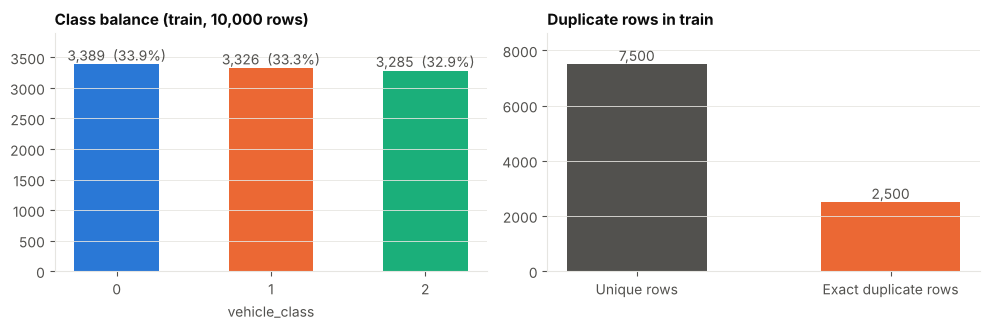

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
vc = train[TARGET].value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=[COL[k] for k in vc.index], width=.55)
for i, v in enumerate(vc.values): ax[0].text(i, v + 60, f"{v:,}  ({v/len(train):.1%})", ha="center", color=INK2)
ax[0].set_title("Class balance (train, 10,000 rows)"); ax[0].set_xlabel("vehicle_class"); ax[0].set_ylim(0, vc.max() * 1.15); ax[0].grid(axis="x", visible=False)
n_dup = len(train) - len(uniq)
ax[1].bar(["Unique rows", "Exact duplicate rows"], [len(uniq), n_dup], color=["#52514e", "#eb6834"], width=.55)
for i, v in enumerate([len(uniq), n_dup]): ax[1].text(i, v + 120, f"{v:,}", ha="center", color=INK2)
ax[1].set_title("Duplicate rows in train"); ax[1].set_ylim(0, len(uniq) * 1.15); ax[1].grid(axis="x", visible=False)
plt.tight_layout(); save("01_class_balance_duplicates")

## 2. Distribution of every feature by class

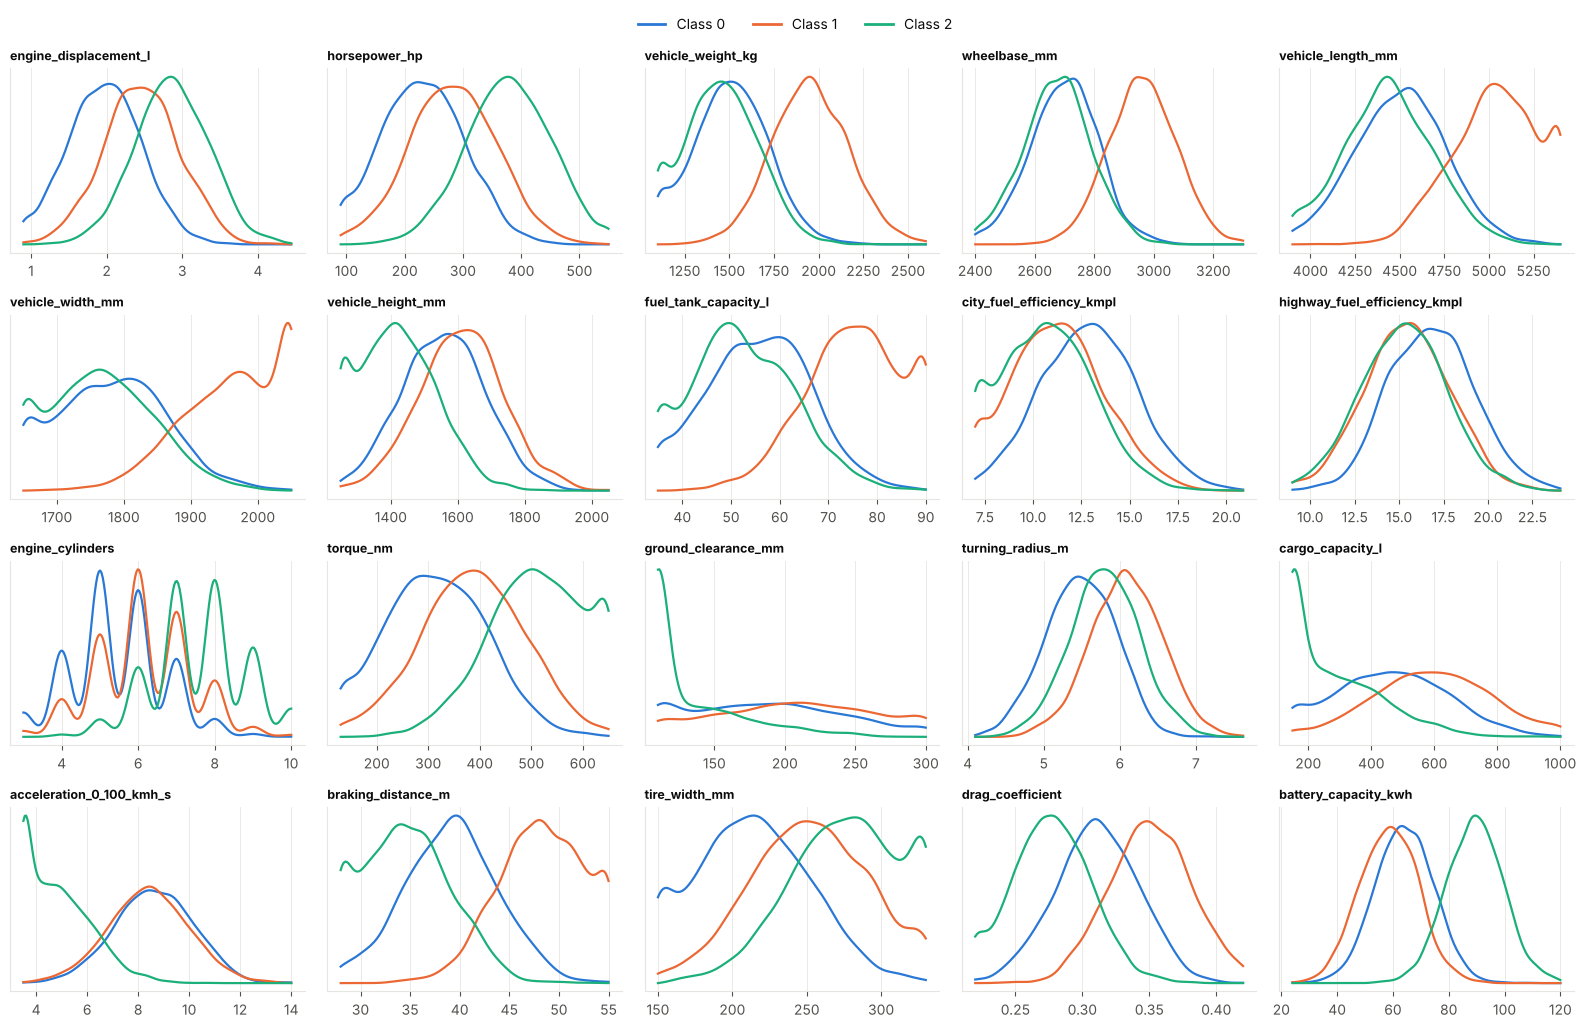

In [3]:
fig, axes = plt.subplots(4, 5, figsize=(16, 10))
for a, c in zip(axes.ravel(), FEATURES):
    for k in COL:
        v = uniq.loc[uniq[TARGET] == k, c]; xs = np.linspace(uniq[c].min(), uniq[c].max(), 200)
        a.plot(xs, stats.gaussian_kde(v)(xs), color=COL[k], lw=1.6)
    a.set_title(c, fontsize=9); a.set_yticks([]); a.grid(axis="y", visible=False)
fig.legend(handles=[mpl.lines.Line2D([], [], color=COL[k], lw=2, label=f"Class {k}") for k in COL], loc="upper center", ncol=3, bbox_to_anchor=(.5, 1.03))
plt.tight_layout(); save("02_feature_distributions_by_class")

## 3. Which features separate the classes? (class means, standardised)

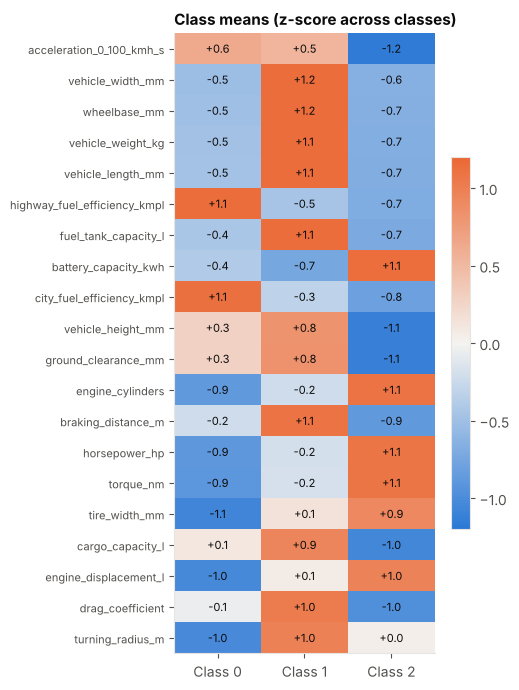

In [4]:
m = uniq.groupby(TARGET)[FEATURES].mean(); z = (m - m.mean()) / m.std()          # z-score of each class mean across the 3 classes
order = (z.abs().max()).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(5.2, 7))
im = ax.imshow(z[order].T.values, cmap=DIV, vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels([f"Class {k}" for k in z.index]); ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
for i in range(len(order)):
    for j in range(3): ax.text(j, i, f"{z[order].T.values[i, j]:+.1f}", ha="center", va="center", fontsize=8, color=INK)
ax.grid(False); ax.set_title("Class means (z-score across classes)"); plt.colorbar(im, ax=ax, shrink=.6)
plt.tight_layout(); save("03_class_mean_heatmap")

## 4. Multicollinearity — why Naive Bayes struggles

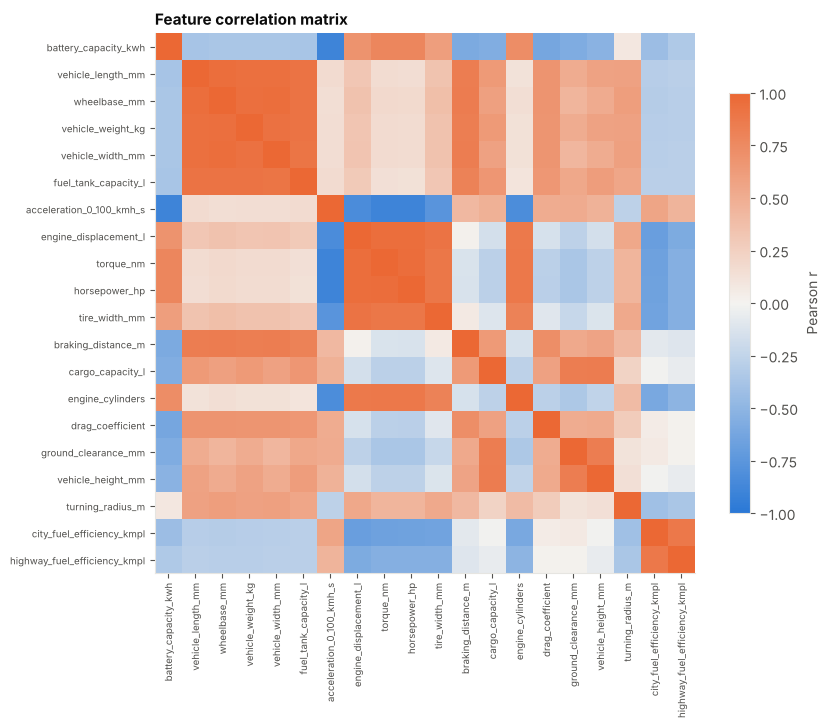

feature pairs with |r| > 0.9: 14


In [5]:
corr = uniq[FEATURES].corr(); o = corr.abs().sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(corr.loc[o, o], cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(20)); ax.set_xticklabels(o, rotation=90, fontsize=7); ax.set_yticks(range(20)); ax.set_yticklabels(o, fontsize=7)
ax.grid(False); ax.set_title("Feature correlation matrix"); plt.colorbar(im, ax=ax, shrink=.7, label="Pearson r")
plt.tight_layout(); save("04_correlation_heatmap")
iu = np.triu_indices(20, 1); print("feature pairs with |r| > 0.9:", int((np.abs(corr.values[iu]) > .9).sum()))

## 5. Can the classes be separated in 2D? (PCA, unsupervised vs LDA, supervised)

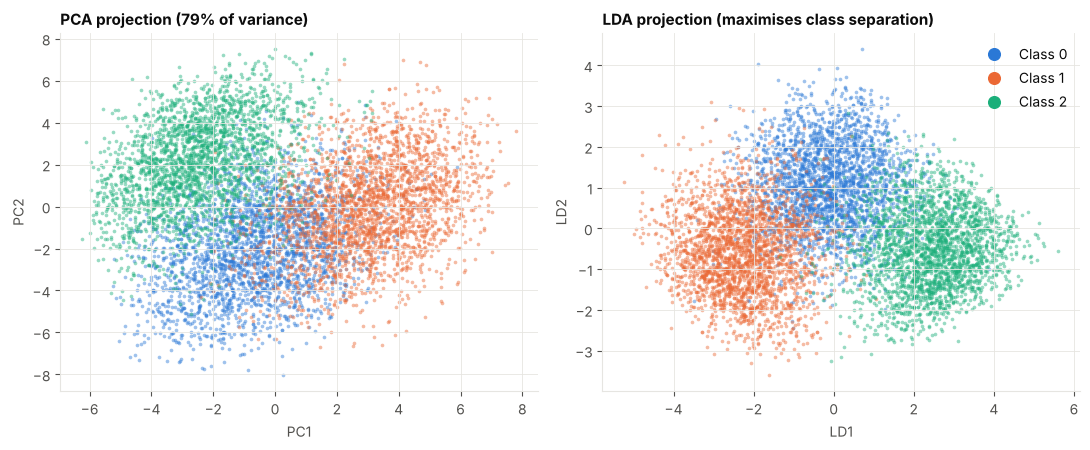

In [6]:
Z = StandardScaler().fit_transform(uniq[FEATURES]); yy = uniq[TARGET].values
P = PCA(2, random_state=SEED).fit(Z); Zp = P.transform(Z); Zl = LinearDiscriminantAnalysis(n_components=2).fit_transform(Z, yy)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, E, t, lab in [(ax[0], Zp, f"PCA projection ({P.explained_variance_ratio_.sum():.0%} of variance)", "PC"), (ax[1], Zl, "LDA projection (maximises class separation)", "LD")]:
    for k in COL: a.scatter(E[yy == k, 0], E[yy == k, 1], s=7, color=COL[k], alpha=.45, linewidths=0)
    a.set_title(t); a.set_xlabel(f"{lab}1"); a.set_ylabel(f"{lab}2")
class_legend(ax[1], loc="best", markerscale=1.4)
plt.tight_layout(); save("05_pca_lda_projection")

## 6. The two most informative single features together

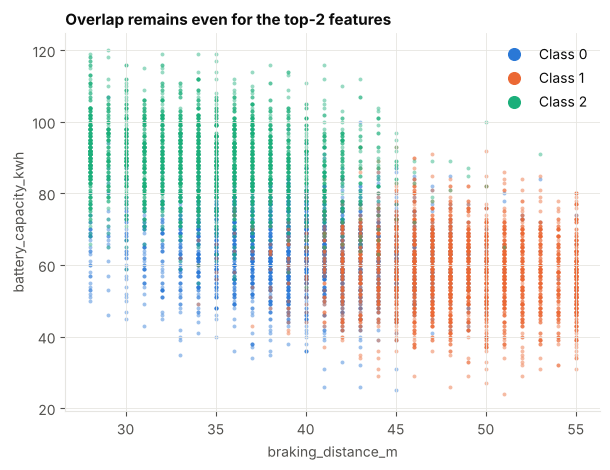

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
for k in COL: ax.scatter(uniq.loc[yy == k, "braking_distance_m"], uniq.loc[yy == k, "battery_capacity_kwh"], s=8, color=COL[k], alpha=.45, linewidths=0)
ax.set_xlabel("braking_distance_m"); ax.set_ylabel("battery_capacity_kwh"); ax.set_title("Overlap remains even for the top-2 features"); class_legend(ax, markerscale=1.4)
plt.tight_layout(); save("06_top2_feature_scatter")

## 7. Bounded values and train-vs-test drift

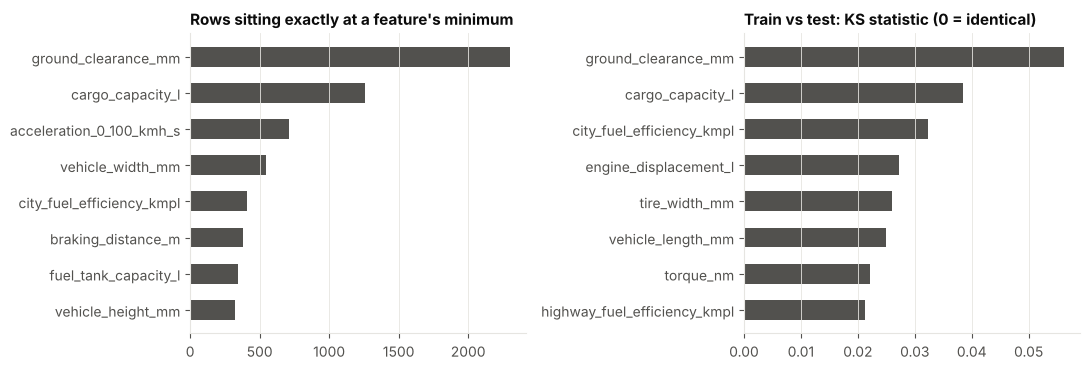

In [8]:
lo = (train[FEATURES] == train[FEATURES].min()).sum().sort_values(ascending=False).head(8)
ks = pd.Series({c: stats.ks_2samp(train[c], test[c]).statistic for c in FEATURES}).sort_values(ascending=False).head(8)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].barh(lo.index[::-1], lo.values[::-1], color="#52514e", height=.55); ax[0].set_title("Rows sitting exactly at a feature's minimum"); ax[0].grid(axis="y", visible=False)
ax[1].barh(ks.index[::-1], ks.values[::-1], color="#52514e", height=.55); ax[1].set_title("Train vs test: KS statistic (0 = identical)"); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); save("07_bounds_and_drift")

## 8. Model results: cross-validation vs Kaggle public score

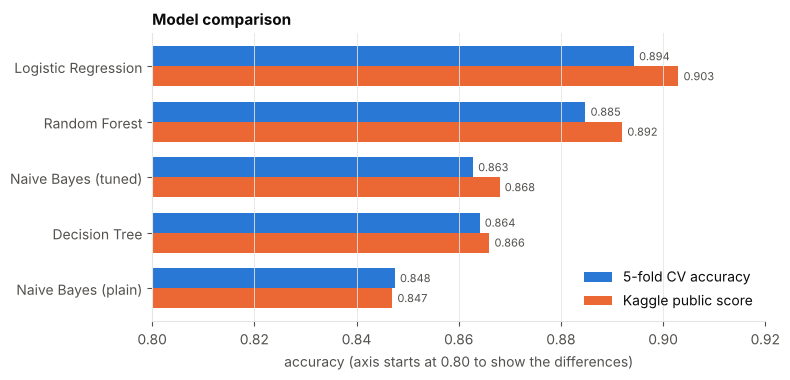

In [9]:
res = pd.DataFrame({"Model": ["Logistic Regression", "Random Forest", "Naive Bayes (tuned)", "Decision Tree", "Naive Bayes (plain)"],
                    "CV accuracy": [0.8943, 0.8848, 0.8628, 0.8641, 0.8475], "Kaggle public score": [0.903, 0.892, 0.868, 0.866, 0.847]})
y_pos = np.arange(len(res)); h = .36
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.barh(y_pos - h/2, res["CV accuracy"], h, color="#2a78d6", label="5-fold CV accuracy")
ax.barh(y_pos + h/2, res["Kaggle public score"], h, color="#eb6834", label="Kaggle public score")
for i, (a, b) in enumerate(zip(res["CV accuracy"], res["Kaggle public score"])):
    ax.text(a + .001, i - h/2, f"{a:.3f}", va="center", fontsize=8, color=INK2); ax.text(b + .001, i + h/2, f"{b:.3f}", va="center", fontsize=8, color=INK2)
ax.set_yticks(y_pos); ax.set_yticklabels(res["Model"]); ax.invert_yaxis(); ax.set_xlim(.80, .92); ax.grid(axis="y", visible=False)
ax.set_xlabel("accuracy (axis starts at 0.80 to show the differences)"); ax.set_title("Model comparison"); ax.legend(loc="lower right"); plt.tight_layout(); save("08_model_comparison")